In [2]:
import sklearn
print(sklearn.__version__)

1.7.2


In [3]:
# ============================================================
# Celda 1: Importación de librerías y configuración inicial
# ============================================================
# En esta celda se importan las librerías necesarias para el análisis
# exploratorio de datos. También se configuran opciones de visualización
# de Pandas, la ruta del dataset y el nombre de la variable objetivo.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.patheffects as path_effects
import math

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATASET_PATH = "dataset-phishing.csv"
TARGET_COL = "status"

sns.set_theme(style="whitegrid")

# Paleta formal utilizada en los gráficos del notebook
COLOR_PRIMARIO = "#3A6EA5"
COLOR_SECUNDARIO = "#5DADE2"
COLOR_TERCIARIO = "#95A5A6"

In [4]:
# ============================================================
# Celda 2: Carga inicial del dataset
# ============================================================
# En esta celda se carga el dataset desde el archivo CSV.
# También se visualiza el tamaño del dataset, las primeras filas
# y las columnas disponibles para verificar que la carga fue correcta.

df = pd.read_csv(DATASET_PATH)

print("Shape del dataset:", df.shape)

print("\nPrimeras filas:")
display(df.head())

print("\nColumnas:")
print(df.columns.tolist())

Shape del dataset: (11430, 89)

Primeras filas:


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,ratio_nullHyperlinks,nb_extCSS,ratio_intRedirection,ratio_extRedirection,ratio_intErrors,ratio_extErrors,login_form,external_favicon,links_in_tags,submit_email,ratio_intMedia,ratio_extMedia,sfh,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,0,0,0,0,3,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,3,0,0,0,0,0,0,4,4,3,3,3,11,11,6,5.750000,7.0,4.500000,0,0,0,0,0,0,17,0.529412,0.470588,0,0,0,0.875000,0,0.500000,0,0,80.000000,0,100.000000,0.000000,0,0,0,0.0,0,0,0,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,0,0,0,0,5,0,1,0,0,0,0,0,0,0,0,1,0.220779,0.0,0,0,0,0,0,1,0,0,0,0,1,0,4,4,2,19,2,32,19,32,15.750000,19.0,14.666667,0,0,0,0,0,0,30,0.966667,0.033333,0,0,0,0.000000,0,0.000000,0,0,100.000000,0,80.000000,20.000000,0,0,0,100.0,0,0,0,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,3,2,0,0,5,0,1,0,0,0,0,0,1,0,0,0,0.150794,0.0,0,0,0,1,0,3,1,0,0,0,1,0,12,2,2,3,2,17,13,17,8.250000,8.4,8.142857,0,0,0,0,0,0,4,1.000000,0.000000,0,0,0,0.000000,0,0.000000,0,0,100.000000,0,0.000000,0.000000,0,0,0,100.0,0,0,0,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,0,0,0,0,2,0,1,0,0,0,0,0,0,0,0,1,0.000000,0.0,0,0,0,0,0,2,0,0,0,0,1,0,1,0,5,5,0,5,5,0,5.000000,5.0,0.000000,0,0,0,0,0,0,149,0.973154,0.026846,0,0,0,0.250000,0,0.250000,0,0,100.000000,0,96.428571,3.571429,0,0,0,62.5,0,0,0,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,0,0,0,0,5,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,2,0,0,0,0,1,0,6,3,3,3,4,11,7,11,6.333333,5.0,7.000000,0,0,0,0,0,0,102,0.470588,0.529412,0,0,0,0.537037,0,0.018519,1,0,76.470588,0,0.000000,100.000000,0,0,0,0.0,0,0,0,0,1,0,224,8175,8725,0,0,6,legitimate



Columnas:
['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'ratio_nullHyperlinks', 'nb_ex

In [5]:
# ============================================================
# Celda 3: Validación de estructura del dataset
# ============================================================
# En esta celda se definen las columnas esperadas del dataset
# y se comparan con las columnas reales cargadas.
# Esto permite detectar columnas faltantes o adicionales
# antes de comenzar el análisis exploratorio.

expected_cols = [
    "url","length_url","length_hostname","ip","nb_dots","nb_hyphens","nb_at","nb_qm",
    "nb_and","nb_or","nb_eq","nb_underscore","nb_tilde","nb_percent","nb_slash",
    "nb_star","nb_colon","nb_comma","nb_semicolumn","nb_dollar","nb_space","nb_www",
    "nb_com","nb_dslash","http_in_path","https_token","ratio_digits_url",
    "ratio_digits_host","punycode","port","tld_in_path","tld_in_subdomain",
    "abnormal_subdomain","nb_subdomains","prefix_suffix","random_domain",
    "shortening_service","path_extension","nb_redirection","nb_external_redirection",
    "length_words_raw","char_repeat","shortest_words_raw","shortest_word_host",
    "shortest_word_path","longest_words_raw","longest_word_host","longest_word_path",
    "avg_words_raw","avg_word_host","avg_word_path","phish_hints","domain_in_brand",
    "brand_in_subdomain","brand_in_path","suspecious_tld","statistical_report",
    "nb_hyperlinks","ratio_intHyperlinks","ratio_extHyperlinks","ratio_nullHyperlinks",
    "nb_extCSS","ratio_intRedirection","ratio_extRedirection","ratio_intErrors",
    "ratio_extErrors","login_form","external_favicon","links_in_tags","submit_email",
    "ratio_intMedia","ratio_extMedia","sfh","iframe","popup_window","safe_anchor",
    "onmouseover","right_clic","empty_title","domain_in_title","domain_with_copyright",
    "whois_registered_domain","domain_registration_length","domain_age","web_traffic",
    "dns_record","google_index","page_rank","status"
]

missing_cols = [c for c in expected_cols if c not in df.columns]
extra_cols = [c for c in df.columns if c not in expected_cols]

print("Columnas faltantes:", missing_cols)
print("Columnas extra:", extra_cols)

Columnas faltantes: []
Columnas extra: []


In [6]:
# ============================================================
# Celda 4: Información general y estadísticas descriptivas
# ============================================================
# En esta celda se analiza la estructura general del dataset,
# incluyendo tipos de datos, cantidad de registros no nulos
# y estadísticas descriptivas de las variables numéricas y categóricas.

print("Información general:")
display(df.info())

print("\nDescripción estadística:")
display(df.describe(include="all").T)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent

None


Descripción estadística:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,11430,11429,http://e710z0ear.du.r.appspot.com/c:/users/use...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
length_url,11430.0,NaN,NaN,NaN,61.126684,55.297318,12.0,33.0,47.0,71.0,1641.0
length_hostname,11430.0,NaN,NaN,NaN,21.090289,10.777171,4.0,15.0,19.0,24.0,214.0
ip,11430.0,NaN,NaN,NaN,0.150569,0.357644,0.0,0.0,0.0,0.0,1.0
nb_dots,11430.0,NaN,NaN,NaN,2.480752,1.369686,1.0,2.0,2.0,3.0,24.0
nb_hyphens,11430.0,NaN,NaN,NaN,0.99755,2.087087,0.0,0.0,0.0,1.0,43.0
nb_at,11430.0,NaN,NaN,NaN,0.022222,0.1555,0.0,0.0,0.0,0.0,4.0
nb_qm,11430.0,NaN,NaN,NaN,0.141207,0.364456,0.0,0.0,0.0,0.0,3.0
nb_and,11430.0,NaN,NaN,NaN,0.162292,0.821337,0.0,0.0,0.0,0.0,19.0
nb_or,11430.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,clase,cantidad,porcentaje
0,legitimate,5715,50.0
1,phishing,5715,50.0


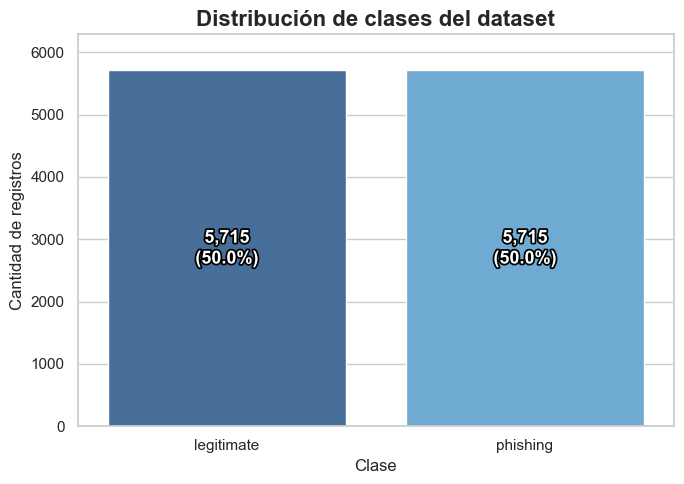

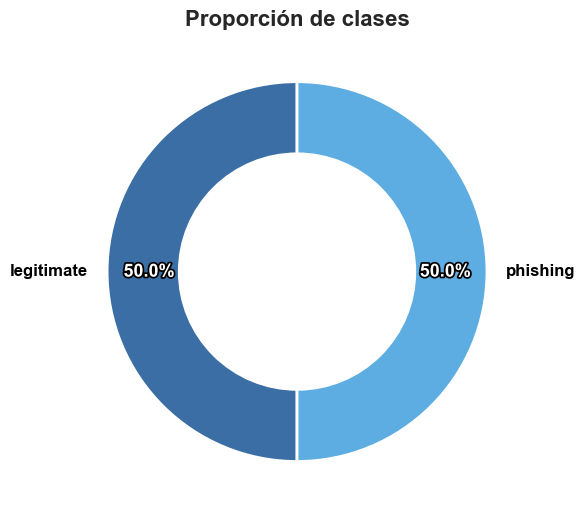

In [7]:
# ============================================================
# Celda 5: Análisis de distribución de la variable objetivo
# ============================================================
# En esta celda se normaliza la variable objetivo y se analiza
# la distribución de clases del dataset. Esto permite verificar
# si el problema está balanceado entre URLs legítimas y phishing.

df[TARGET_COL] = (
    df[TARGET_COL]
    .astype(str)
    .str.lower()
    .str.strip()
)

target_counts = df[TARGET_COL].value_counts()
target_percent = df[TARGET_COL].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "clase": target_counts.index,
    "cantidad": target_counts.values,
    "porcentaje": target_percent.values.round(2)
})

display(target_summary)

colors = [COLOR_PRIMARIO, COLOR_SECUNDARIO]

# Gráfico de barras
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=target_summary,
    x="clase",
    y="cantidad",
    hue="clase",
    palette=colors,
    legend=False
)

plt.title("Distribución de clases del dataset", fontsize=16, fontweight="bold")
plt.xlabel("Clase", fontsize=12)
plt.ylabel("Cantidad de registros", fontsize=12)

for i, row in target_summary.iterrows():
    ax.text(
        i,
        row["cantidad"] * 0.5,
        f'{int(row["cantidad"]):,}\n({row["porcentaje"]:.1f}%)',
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        color="white",
        path_effects=[
            path_effects.Stroke(linewidth=2.5, foreground="black"),
            path_effects.Normal()
        ]
    )

plt.ylim(0, target_summary["cantidad"].max() * 1.10)
plt.tight_layout()
plt.show()

# Gráfico donut
plt.figure(figsize=(6, 6))

wedges, texts, autotexts = plt.pie(
    target_summary["cantidad"],
    labels=target_summary["clase"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.78,
    labeldistance=1.10,
    wedgeprops={"width": 0.38, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12, "fontweight": "bold"}
)

for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(13)
    autotext.set_path_effects([
        path_effects.Stroke(linewidth=2.5, foreground="black"),
        path_effects.Normal()
    ])

for text in texts:
    text.set_color("black")
    text.set_fontsize(12)
    text.set_fontweight("bold")

plt.title("Proporción de clases", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# Celda 6: Análisis de duplicados
# ============================================================
# En esta celda se revisa si existen filas completamente duplicadas
# y si hay URLs repetidas. Además, se muestran las URLs duplicadas,
# cuántas veces aparecen y los registros asociados.

print("Filas duplicadas completas:", df.duplicated().sum())

if "url" in df.columns:
    print("URLs duplicadas:", df["url"].duplicated().sum())

    url_counts = df["url"].value_counts()
    duplicated_url_counts = url_counts[url_counts > 1]

    print("\nURLs repetidas y cantidad de apariciones:")
    display(duplicated_url_counts)

    duplicated_urls = df[df["url"].duplicated(keep=False)].sort_values("url")

    print("\nRegistros asociados a URLs duplicadas:")
    display(duplicated_urls)

Filas duplicadas completas: 0
URLs duplicadas: 1

URLs repetidas y cantidad de apariciones:


url
http://e710z0ear.du.r.appspot.com/c:/users/user/downlo    2
Name: count, dtype: int64


Registros asociados a URLs duplicadas:


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,ratio_nullHyperlinks,nb_extCSS,ratio_intRedirection,ratio_extRedirection,ratio_intErrors,ratio_extErrors,login_form,external_favicon,links_in_tags,submit_email,ratio_intMedia,ratio_extMedia,sfh,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
6035,http://e710z0ear.du.r.appspot.com/c:/users/use...,62,26,0,4,0,0,0,0,0,0,0,0,0,6,0,2,0,0,0,0,0,0,0,0,1,0.064516,0.153846,0,0,0,0,0,3,0,0,1,0,0,0,8,2,1,1,1,14,9,14,5.375,4.75,6.0,0,0,0,0,0,0,21,0.190476,0.809524,0,1,0,0.294118,0,0.0,0,1,0.0,0,20.0,80.0,0,0,0,25.0,0,0,0,1,1,0,217,5627,0,0,1,5,phishing
11305,http://e710z0ear.du.r.appspot.com/c:/users/use...,54,26,0,4,0,0,0,0,0,0,0,0,0,6,0,2,0,0,0,0,0,0,0,0,1,0.074074,0.153846,0,0,0,0,0,3,0,0,1,0,0,0,8,1,1,1,1,9,9,6,4.375,4.75,4.0,0,0,0,0,0,0,21,0.190476,0.809524,0,1,0,0.176471,0,0.0,0,1,0.0,0,20.0,80.0,0,0,0,25.0,0,0,0,1,1,0,230,5614,0,0,1,5,phishing


In [9]:
# ============================================================
# Celda 7: Análisis de completitud del dataset
# ============================================================
# En esta celda se analiza la presencia de valores nulos en el dataset.
# Se calcula la cantidad y porcentaje de valores faltantes por variable.
# Si existen nulos, se visualizan en un gráfico; si no, se informa que
# el dataset está completo.

valores_nulos = df.isnull().sum()
porcentaje_nulos = (valores_nulos / len(df)) * 100

nulos_df = pd.DataFrame({
    "Valores Nulos": valores_nulos,
    "Porcentaje de Nulos (%)": porcentaje_nulos.round(2)
}).sort_values("Porcentaje de Nulos (%)", ascending=False)

nulos_con_datos = nulos_df[nulos_df["Valores Nulos"] > 0]

print("Completitud del dataset:")
display(nulos_df)

if nulos_con_datos.empty:
    print("No existen valores nulos en el dataset.")
else:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=nulos_con_datos.reset_index(),
        x="index",
        y="Porcentaje de Nulos (%)",
        color=COLOR_PRIMARIO
    )
    plt.xticks(rotation=90)
    plt.title("Porcentaje de valores nulos por columna", fontsize=15, fontweight="bold")
    plt.xlabel("Columnas")
    plt.ylabel("Porcentaje de nulos (%)")
    plt.tight_layout()
    plt.show()

Completitud del dataset:


,Valores Nulos,Porcentaje de Nulos (%)
url,0,0.0
longest_words_raw,0,0.0
ratio_extErrors,0,0.0
ratio_intErrors,0,0.0
ratio_extRedirection,0,0.0
ratio_intRedirection,0,0.0
nb_extCSS,0,0.0
ratio_nullHyperlinks,0,0.0
ratio_extHyperlinks,0,0.0
ratio_intHyperlinks,0,0.0


No existen valores nulos en el dataset.


In [10]:
# ============================================================
# Celda 8: Análisis de correctitud mediante valores negativos
# ============================================================
# En esta celda se identifican variables numéricas que contienen valores negativos.
# Esto es importante porque algunas características deberían ser naturalmente
# positivas, como conteos, longitudes o cantidades. Los valores negativos pueden
# representar errores, valores especiales o códigos usados por el dataset.

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

negative_report = []

for col in numeric_cols:
    negative_count = (df[col] < 0).sum()
    
    if negative_count > 0:
        negative_report.append({
            "feature": col,
            "negative_count": negative_count,
            "negative_percent": round(negative_count / len(df) * 100, 2),
            "min_value": df[col].min()
        })

negative_report_df = pd.DataFrame(negative_report)

display(negative_report_df)

if negative_report_df.empty:
    print("No se encontraron valores negativos en variables numéricas.")
else:
    print("Se encontraron variables con valores negativos. Revisar si corresponden a valores especiales o errores.")

,feature,negative_count,negative_percent,min_value
0,domain_registration_length,46,0.40,-1
1,domain_age,1837,16.07,-12


Se encontraron variables con valores negativos. Revisar si corresponden a valores especiales o errores.


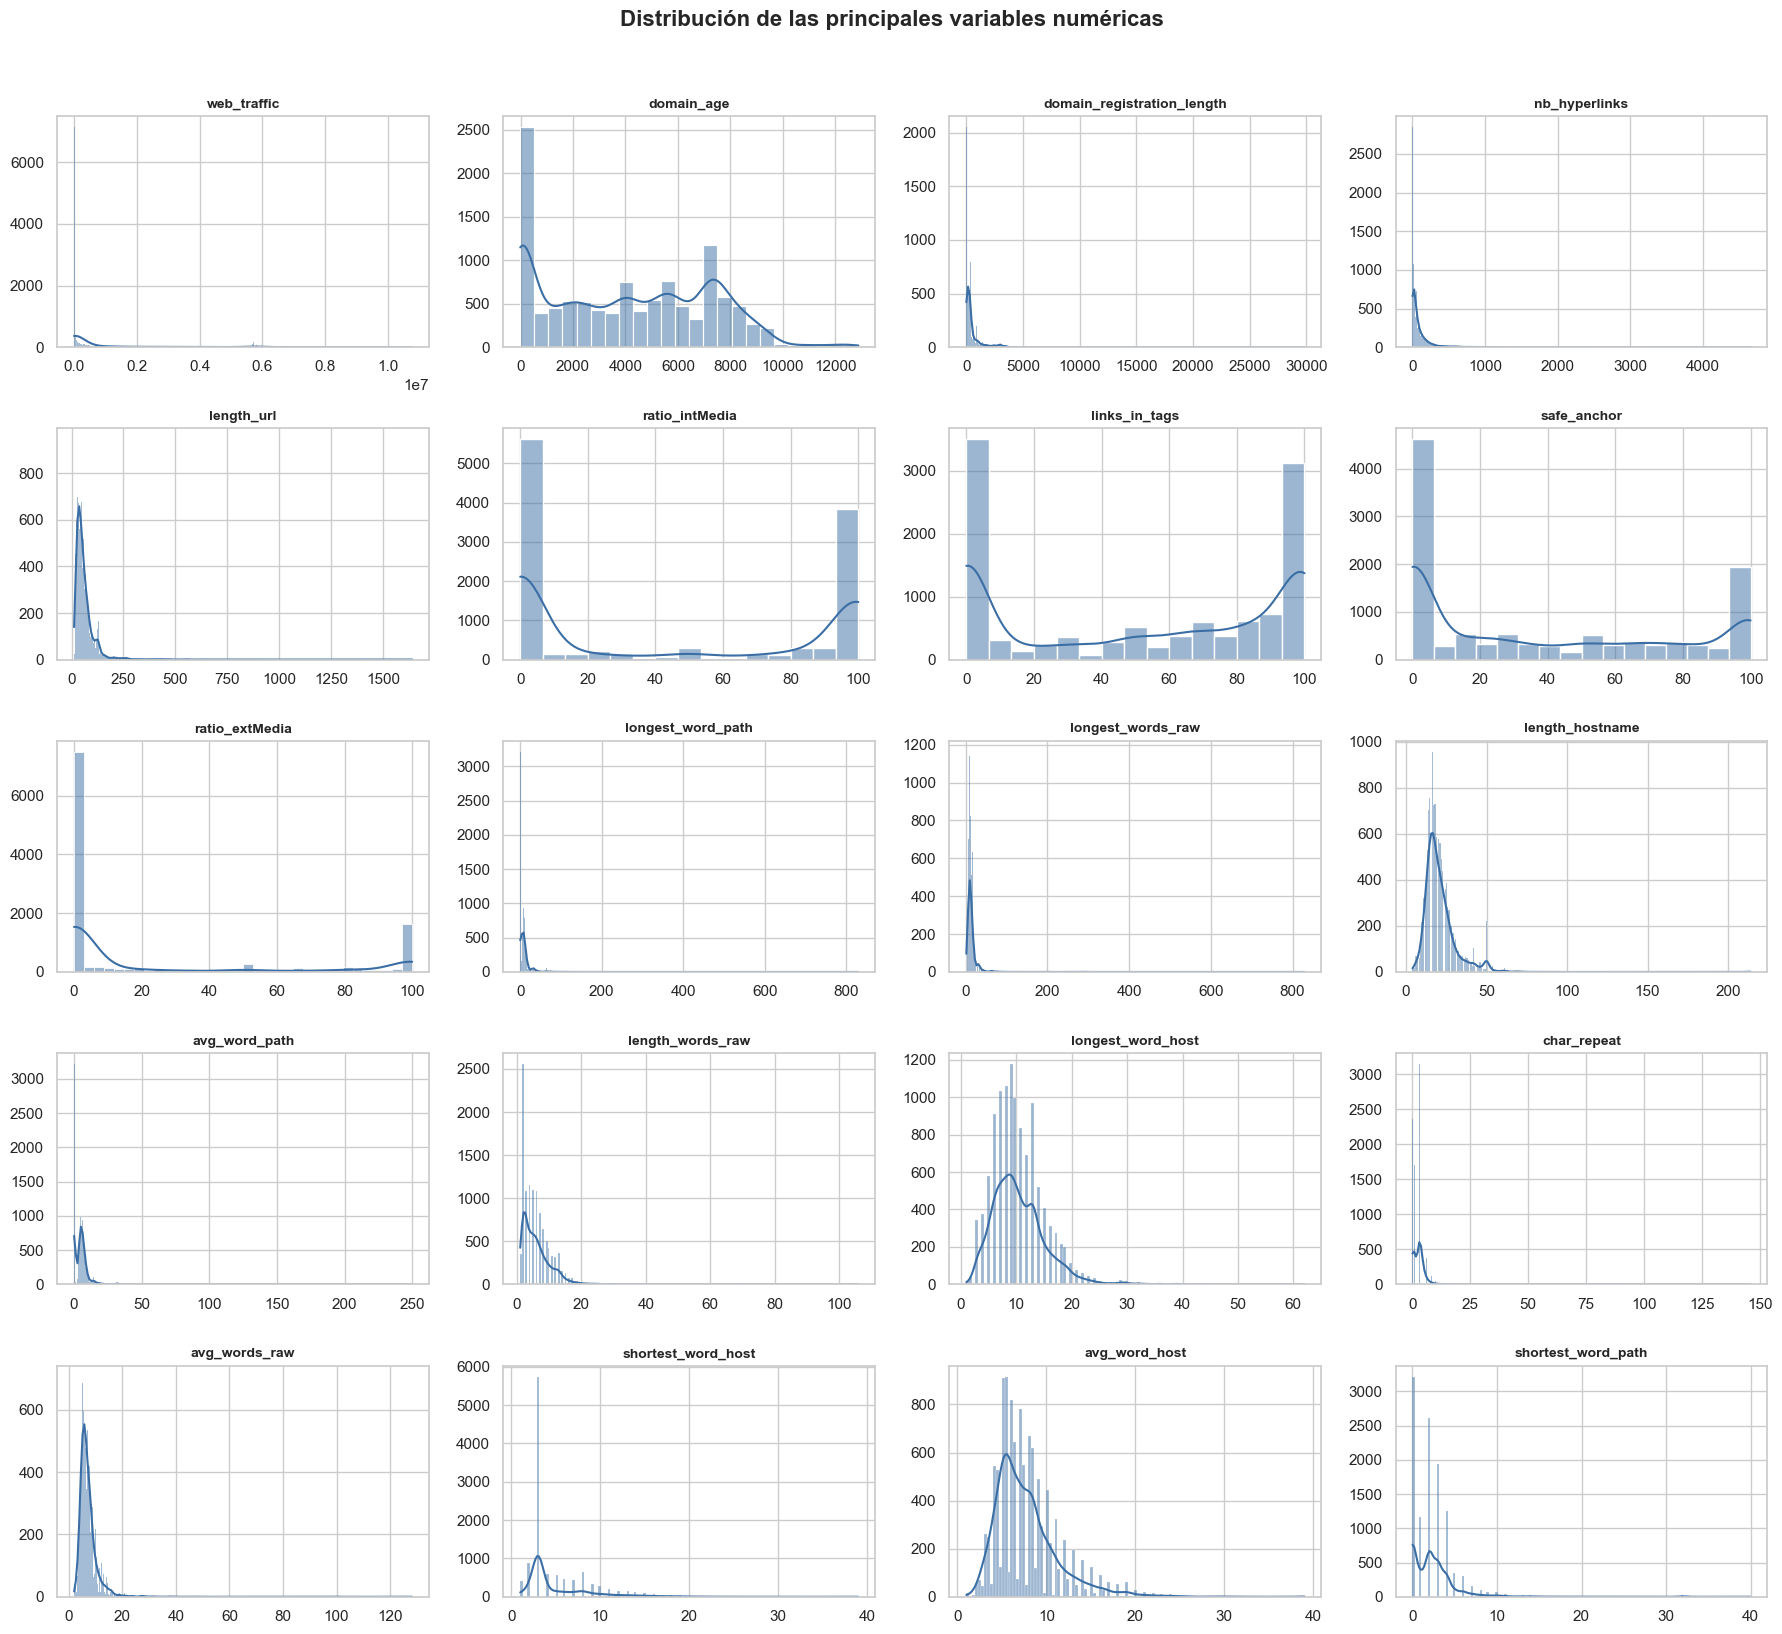

In [11]:
# ============================================================
# Celda 9: Distribución de variables numéricas principales
# ============================================================
# En esta celda se visualiza la distribución de las variables numéricas.
# Para evitar un gráfico excesivamente grande, se seleccionan las variables
# con mayor desviación estándar, ya que suelen mostrar mayor variabilidad.

num_cols = df.select_dtypes(include=["float64", "int64"]).columns

top_num_cols = (
    df[num_cols]
    .std()
    .sort_values(ascending=False)
    .head(20)
    .index
)

cols = 4
rows = math.ceil(len(top_num_cols) / cols)

plt.figure(figsize=(cols * 4.5, rows * 3.2))

for i, col in enumerate(top_num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(df[col], kde=True, color=COLOR_PRIMARIO)
    plt.title(col, fontsize=10, fontweight="bold")
    plt.xlabel("")
    plt.ylabel("")

plt.suptitle(
    "Distribución de las principales variables numéricas",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# Celda 10: Identificación de variables constantes
# ============================================================
# En esta celda se identifican variables que poseen un único valor en todo
# el dataset. Estas variables no aportan información predictiva al modelo,
# por lo que posteriormente podrían eliminarse en la etapa de limpieza.

unique_counts = df.nunique().sort_values()

constant_features = unique_counts[unique_counts <= 1]

print("Variables constantes:")
display(constant_features)

print("Cantidad:", len(constant_features))

if len(constant_features) == 0:
    print("No se encontraron variables constantes.")
else:
    print("Estas variables podrían eliminarse en la etapa de preparación de datos.")

Variables constantes:


ratio_nullHyperlinks    1
ratio_intErrors         1
ratio_intRedirection    1
submit_email            1
nb_or                   1
sfh                     1
dtype: int64

Cantidad: 6
Estas variables podrían eliminarse en la etapa de preparación de datos.


,feature,outliers,outlier_percent,min,max
78,domain_in_title,2562,22.41,0.0,1.000000e+00
33,prefix_suffix,2314,20.24,0.0,1.000000e+00
64,ratio_extErrors,2149,18.80,0.0,1.000000e+00
83,web_traffic,2138,18.71,0.0,1.076799e+07
50,phish_hints,2041,17.86,0.0,1.000000e+01
70,ratio_extMedia,2012,17.60,0.0,1.000000e+02
2,ip,1721,15.06,0.0,1.000000e+00
10,nb_underscore,1695,14.83,0.0,1.800000e+01
9,nb_eq,1564,13.68,0.0,1.900000e+01
6,nb_qm,1555,13.60,0.0,3.000000e+00


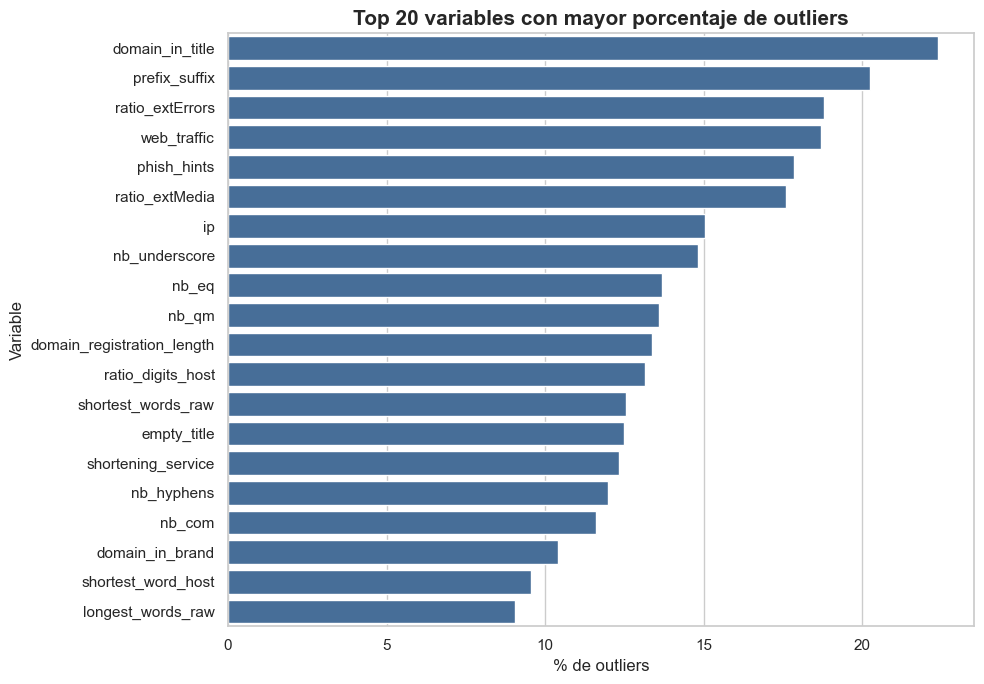

In [13]:
# ============================================================
# Celda 11: Detección de outliers mediante el método IQR
# ============================================================
# En esta celda se identifican valores atípicos (outliers) en las variables
# numéricas utilizando el método del rango intercuartílico (IQR).
# Esto permite detectar variables con distribuciones extremas o anómalas
# que podrían afectar el entrenamiento de modelos de Machine Learning.

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

outlier_report = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    
    outlier_report.append({
        "feature": col,
        "outliers": outliers,
        "outlier_percent": round(outliers / len(df) * 100, 2),
        "min": df[col].min(),
        "max": df[col].max()
    })

outlier_df = pd.DataFrame(outlier_report).sort_values(
    "outlier_percent",
    ascending=False
)

display(outlier_df.head(30))

# =========================
# Gráfico de outliers
# =========================

plt.figure(figsize=(10, 7))

sns.barplot(
    data=outlier_df.head(20),
    y="feature",
    x="outlier_percent",
    color=COLOR_PRIMARIO
)

plt.title(
    "Top 20 variables con mayor porcentaje de outliers",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("% de outliers")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

google_index             0.731171
page_rank               -0.511137
nb_www                  -0.443468
ratio_digits_url         0.356395
domain_in_title          0.342807
nb_hyperlinks           -0.342628
phish_hints              0.335393
domain_age              -0.331889
ip                       0.321698
nb_qm                    0.294319
length_url               0.248580
ratio_intHyperlinks     -0.243982
nb_slash                 0.242270
length_hostname          0.238322
nb_eq                    0.233386
ratio_digits_host        0.224335
shortest_word_host       0.223084
prefix_suffix            0.214681
longest_word_path        0.212709
tld_in_subdomain         0.208884
empty_title              0.207043
nb_dots                  0.207029
longest_words_raw        0.200147
avg_word_path            0.197256
avg_word_host            0.193502
ratio_intMedia          -0.193333
length_words_raw         0.192010
links_in_tags           -0.184401
safe_anchor             -0.173397
domain_with_co

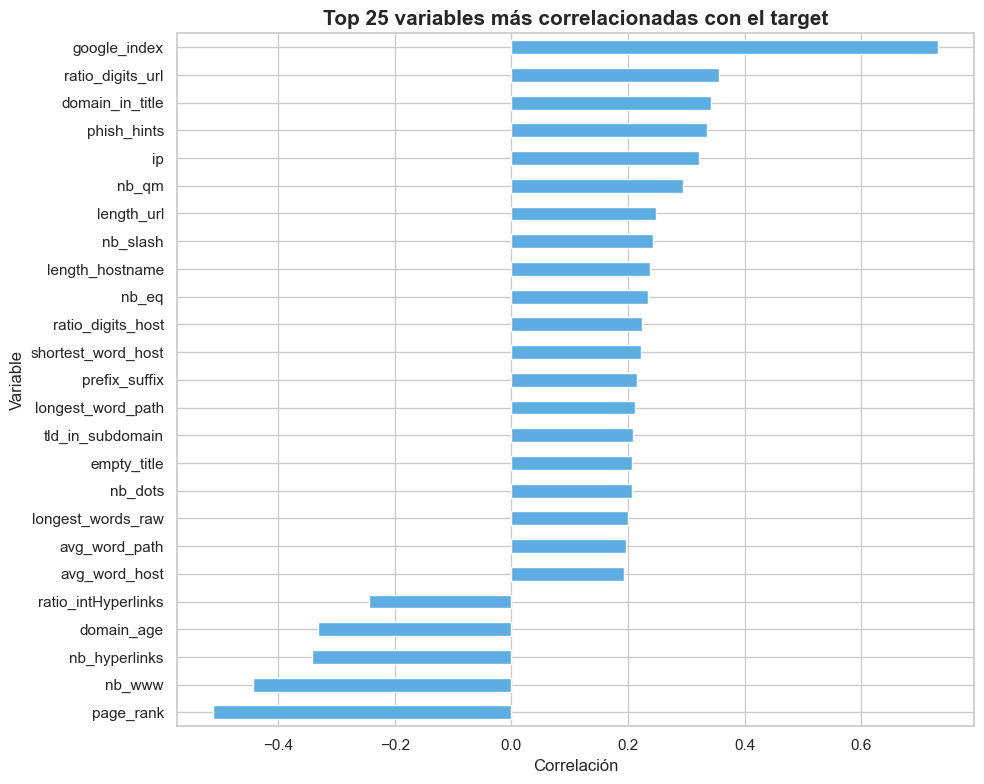

In [14]:
# ============================================================
# Celda 12: Correlación de variables con la variable objetivo
# ============================================================
# En esta celda se convierte la variable objetivo a formato numérico
# para calcular la correlación de cada característica con la clase.
# Este análisis permite identificar variables con mayor relación lineal
# respecto a la detección de phishing.

df_corr = df.copy()

df_corr[TARGET_COL] = df_corr[TARGET_COL].map({
    "legitimate": 0,
    "phishing": 1
})

df_corr = df_corr.drop(columns=["url"], errors="ignore")

for col in df_corr.columns:
    df_corr[col] = pd.to_numeric(df_corr[col], errors="coerce")

corr_target = (
    df_corr
    .corr(numeric_only=True)[TARGET_COL]
    .drop(TARGET_COL)
    .sort_values(key=abs, ascending=False)
)

display(corr_target.head(30))

# =========================
# Gráfico de correlación con el target
# =========================

plt.figure(figsize=(10, 8))

corr_target.head(25).sort_values().plot(
    kind="barh",
    color=COLOR_SECUNDARIO
)

plt.title(
    "Top 25 variables más correlacionadas con el target",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Correlación")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# Celda 13: Separación de características por tipo
# ============================================================
# En esta celda se agrupan las variables según su origen:
# características de URL, características HTML y características de servicios externos.
# Esta separación permite analizar cada grupo de manera independiente.

url_features = [
    "length_url", "length_hostname", "ip", "nb_dots", "nb_hyphens",
    "nb_at", "nb_qm", "nb_and", "nb_or", "nb_eq", "nb_underscore",
    "nb_tilde", "nb_percent", "nb_slash", "nb_star", "nb_colon",
    "nb_comma", "nb_semicolumn", "nb_dollar", "nb_space", "nb_www",
    "nb_com", "nb_dslash", "http_in_path", "https_token",
    "ratio_digits_url", "ratio_digits_host", "punycode", "port",
    "tld_in_path", "tld_in_subdomain", "abnormal_subdomain",
    "nb_subdomains", "prefix_suffix", "random_domain",
    "shortening_service", "path_extension", "nb_redirection",
    "nb_external_redirection", "length_words_raw", "char_repeat",
    "shortest_words_raw", "shortest_word_host", "shortest_word_path",
    "longest_words_raw", "longest_word_host", "longest_word_path",
    "avg_words_raw", "avg_word_host", "avg_word_path", "phish_hints",
    "domain_in_brand", "brand_in_subdomain", "brand_in_path",
    "suspecious_tld", "statistical_report"
]

html_features = [
    "nb_hyperlinks", "ratio_intHyperlinks", "ratio_extHyperlinks",
    "ratio_nullHyperlinks", "nb_extCSS", "ratio_intRedirection",
    "ratio_extRedirection", "ratio_intErrors", "ratio_extErrors",
    "login_form", "external_favicon", "links_in_tags", "submit_email",
    "ratio_intMedia", "ratio_extMedia", "sfh", "iframe",
    "popup_window", "safe_anchor", "onmouseover", "right_clic",
    "empty_title", "domain_in_title", "domain_with_copyright"
]

service_features = [
    "whois_registered_domain", "domain_registration_length",
    "domain_age", "web_traffic", "dns_record", "google_index",
    "page_rank"
]

url_features = [col for col in url_features if col in df.columns]
html_features = [col for col in html_features if col in df.columns]
service_features = [col for col in service_features if col in df.columns]

feature_group_summary = pd.DataFrame({
    "grupo": ["URL", "HTML", "Servicios externos"],
    "cantidad_features": [
        len(url_features),
        len(html_features),
        len(service_features)
    ]
})

display(feature_group_summary)

,grupo,cantidad_features
0,URL,56
1,HTML,24
2,Servicios externos,7


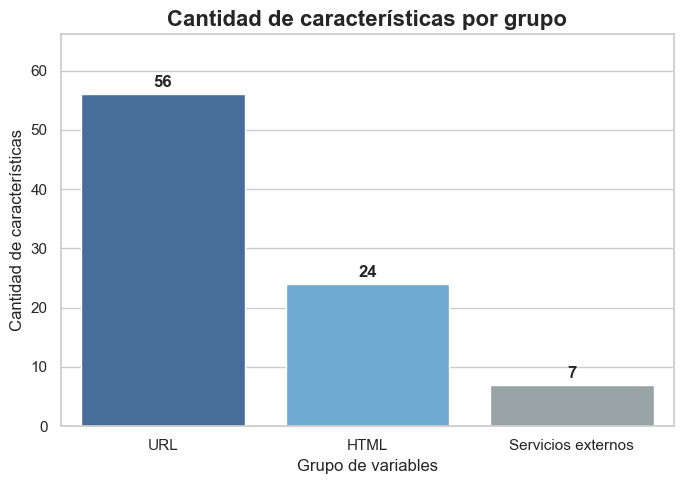

In [16]:
# ============================================================
# Celda 14: Visualización de grupos de características
# ============================================================
# En esta celda se visualiza la cantidad de características disponibles
# para cada grupo. Esto permite entender la composición del dataset
# según el origen de las variables.

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=feature_group_summary,
    x="grupo",
    y="cantidad_features",
    hue="grupo",
    palette=[COLOR_PRIMARIO, COLOR_SECUNDARIO, "#95A5A6"],
    legend=False
)

plt.title("Cantidad de características por grupo", fontsize=16, fontweight="bold")
plt.xlabel("Grupo de variables")
plt.ylabel("Cantidad de características")

for i, row in feature_group_summary.iterrows():
    ax.text(
        i,
        row["cantidad_features"] + 0.7,
        int(row["cantidad_features"]),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.ylim(0, feature_group_summary["cantidad_features"].max() * 1.18)
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# Celda 15: Resumen estadístico por grupo de variables
# ============================================================
# En esta celda se genera un resumen estadístico independiente
# para las variables de URL, HTML y servicios externos.

def resumen_grupo(df, features, nombre_grupo):
    print(f"\n========== {nombre_grupo.upper()} ==========")
    
    resumen = df[features].describe().T
    resumen["missing"] = df[features].isnull().sum()
    resumen["unique"] = df[features].nunique()
    
    display(resumen)

resumen_grupo(df, url_features, "Características de URL")
resumen_grupo(df, html_features, "Características HTML")
resumen_grupo(df, service_features, "Características de servicios externos")


========== CARACTERÍSTICAS DE URL ==========


,count,mean,std,min,25%,50%,75%,max,missing,unique
length_url,11430.0,61.126684,55.297318,12.0,33.00,47.000000,71.000000,1641.000000,0,324
length_hostname,11430.0,21.090289,10.777171,4.0,15.00,19.000000,24.000000,214.000000,0,83
ip,11430.0,0.150569,0.357644,0.0,0.00,0.000000,0.000000,1.000000,0,2
nb_dots,11430.0,2.480752,1.369686,1.0,2.00,2.000000,3.000000,24.000000,0,19
nb_hyphens,11430.0,0.997550,2.087087,0.0,0.00,0.000000,1.000000,43.000000,0,27
nb_at,11430.0,0.022222,0.155500,0.0,0.00,0.000000,0.000000,4.000000,0,5
nb_qm,11430.0,0.141207,0.364456,0.0,0.00,0.000000,0.000000,3.000000,0,4
nb_and,11430.0,0.162292,0.821337,0.0,0.00,0.000000,0.000000,19.000000,0,15
nb_or,11430.0,0.000000,0.000000,0.0,0.00,0.000000,0.000000,0.000000,0,1
nb_eq,11430.0,0.293176,0.998317,0.0,0.00,0.000000,0.000000,19.000000,0,16



========== CARACTERÍSTICAS HTML ==========


,count,mean,std,min,25%,50%,75%,max,missing,unique
nb_hyperlinks,11430.0,87.189764,166.758254,0.0,9.000000,34.000000,101.000000,4659.0,0,691
ratio_intHyperlinks,11430.0,0.602457,0.376474,0.0,0.224991,0.743442,0.944767,1.0,0,3131
ratio_extHyperlinks,11430.0,0.276720,0.319958,0.0,0.000000,0.131148,0.474840,1.0,0,3131
ratio_nullHyperlinks,11430.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0,1
nb_extCSS,11430.0,0.784864,2.758802,0.0,0.000000,0.000000,1.000000,124.0,0,33
ratio_intRedirection,11430.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0,1
ratio_extRedirection,11430.0,0.158926,0.266437,0.0,0.000000,0.000000,0.230769,2.0,0,894
ratio_intErrors,11430.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0,1
ratio_extErrors,11430.0,0.062469,0.156209,0.0,0.000000,0.000000,0.034483,1.0,0,635
login_form,11430.0,0.063605,0.244058,0.0,0.000000,0.000000,0.000000,1.0,0,2



========== CARACTERÍSTICAS DE SERVICIOS EXTERNOS ==========


,count,mean,std,min,25%,50%,75%,max,missing,unique
whois_registered_domain,11430.0,0.072878,2.599482e-01,0.0,0.00,0.0,0.00,1.0,0,2
domain_registration_length,11430.0,492.532196,8.147694e+02,-1.0,84.00,242.0,449.00,29829.0,0,1659
domain_age,11430.0,4062.543745,3.107785e+03,-12.0,972.25,3993.0,7026.75,12874.0,0,4430
web_traffic,11430.0,856756.643307,1.995606e+06,0.0,0.00,1651.0,373845.50,10767986.0,0,4744
dns_record,11430.0,0.020122,1.404254e-01,0.0,0.00,0.0,0.00,1.0,0,2
google_index,11430.0,0.533946,4.988682e-01,0.0,0.00,1.0,1.00,1.0,0,2
page_rank,11430.0,3.185739,2.536955e+00,0.0,1.00,3.0,5.00,10.0,0,11



========== TOP CORRELACIONES: URL ==========


nb_www               -0.443468
ratio_digits_url      0.356395
phish_hints           0.335393
ip                    0.321698
nb_qm                 0.294319
length_url            0.248580
nb_slash              0.242270
length_hostname       0.238322
nb_eq                 0.233386
ratio_digits_host     0.224335
shortest_word_host    0.223084
prefix_suffix         0.214681
longest_word_path     0.212709
tld_in_subdomain      0.208884
nb_dots               0.207029
Name: status, dtype: float64

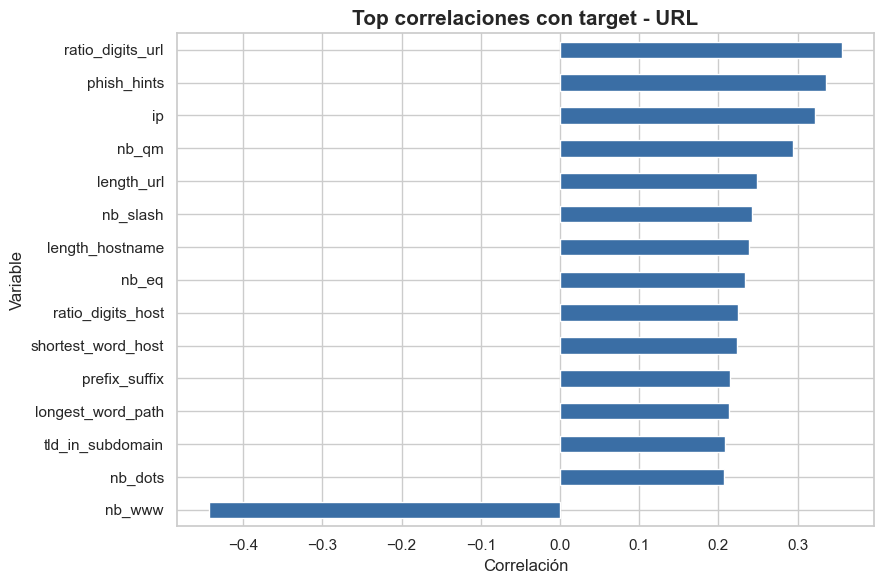


========== TOP CORRELACIONES: HTML ==========


domain_in_title          0.342807
nb_hyperlinks           -0.342628
ratio_intHyperlinks     -0.243982
empty_title              0.207043
ratio_intMedia          -0.193333
links_in_tags           -0.184401
safe_anchor             -0.173397
domain_with_copyright   -0.173098
ratio_extRedirection    -0.150827
external_favicon        -0.146565
ratio_extMedia          -0.140406
nb_extCSS               -0.083567
ratio_extHyperlinks      0.083357
popup_window            -0.057602
ratio_extErrors         -0.034703
Name: status, dtype: float64

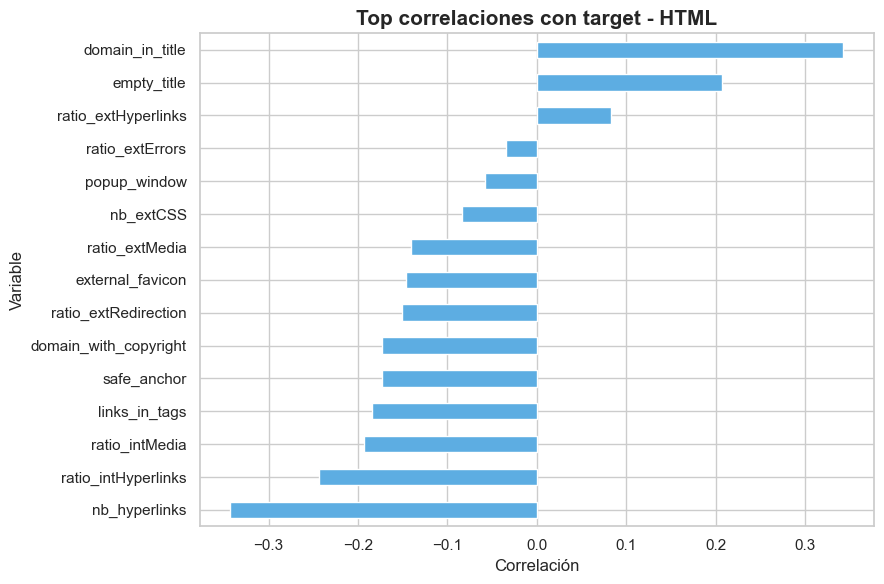


========== TOP CORRELACIONES: SERVICIOS EXTERNOS ==========


google_index                  0.731171
page_rank                    -0.511137
domain_age                   -0.331889
domain_registration_length   -0.161719
dns_record                    0.122119
whois_registered_domain       0.066979
web_traffic                   0.060388
Name: status, dtype: float64

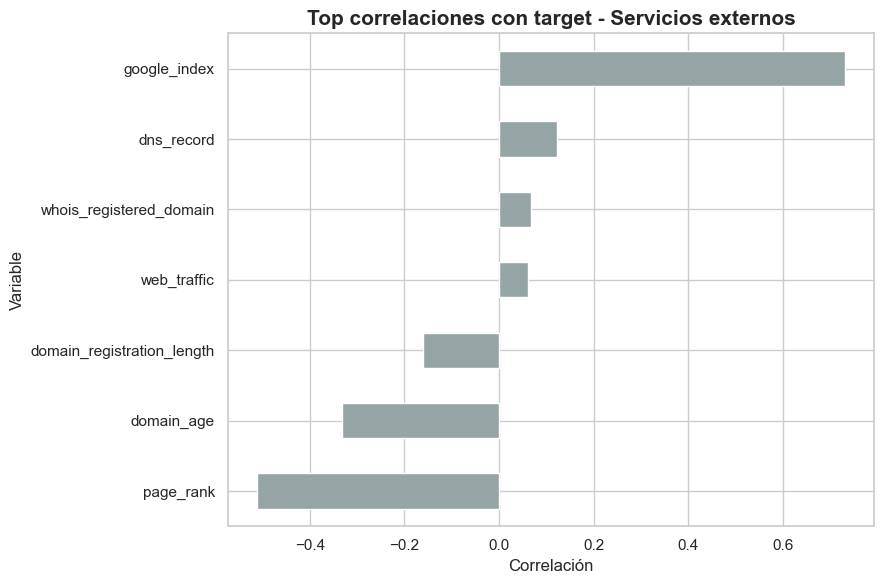

In [18]:
# ============================================================
# Celda 16: Correlación con target por grupo de variables
# ============================================================
# En esta celda se analiza qué variables de cada grupo presentan
# mayor correlación con la variable objetivo.

def correlacion_target_grupo(corr_target, features, nombre_grupo, color):
    corr_group = corr_target[corr_target.index.isin(features)]
    corr_group = corr_group.sort_values(key=abs, ascending=False)

    print(f"\n========== TOP CORRELACIONES: {nombre_grupo.upper()} ==========")
    display(corr_group.head(15))

    plt.figure(figsize=(9, 6))
    corr_group.head(15).sort_values().plot(
        kind="barh",
        color=color
    )

    plt.title(
        f"Top correlaciones con target - {nombre_grupo}",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Correlación")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.show()

correlacion_target_grupo(corr_target, url_features, "URL", COLOR_PRIMARIO)
correlacion_target_grupo(corr_target, html_features, "HTML", COLOR_SECUNDARIO)
correlacion_target_grupo(corr_target, service_features, "Servicios externos", COLOR_TERCIARIO)

In [19]:
# ============================================================
# Celda 17: Detección de variables altamente correlacionadas
# ============================================================
# En esta celda se identifican pares de variables con alta correlación
# entre sí. Esto permite detectar redundancia entre características,
# lo que puede ser útil para la etapa de selección de variables.

feature_cols = [col for col in df_corr.columns if col != TARGET_COL]

corr_matrix = df_corr[feature_cols].corr(numeric_only=True).abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = []

for col in upper_triangle.columns:
    correlated_features = upper_triangle.index[upper_triangle[col] > 0.90].tolist()
    
    for row in correlated_features:
        high_corr_pairs.append({
            "feature_1": row,
            "feature_2": col,
            "correlation": upper_triangle.loc[row, col]
        })

high_corr_df = pd.DataFrame(high_corr_pairs)

if high_corr_df.empty:
    print("No se encontraron pares de variables con correlación superior a 0.90.")
else:
    high_corr_df = high_corr_df.sort_values("correlation", ascending=False)
    display(high_corr_df.head(50))

,feature_1,feature_2,correlation
1,longest_words_raw,longest_word_path,0.968503
0,nb_and,nb_eq,0.906404


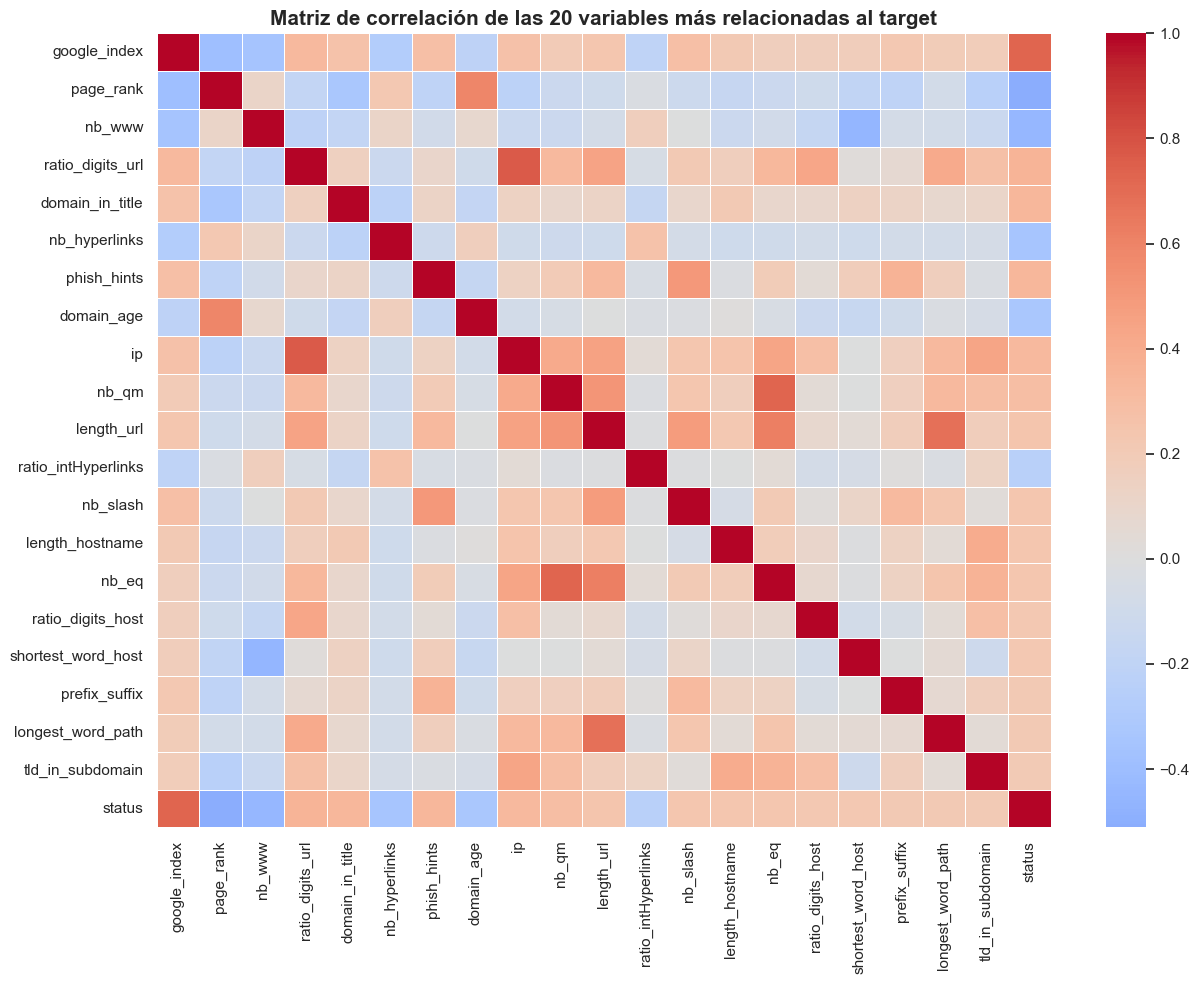

In [20]:
# ============================================================
# Celda 18: Mapa de correlación de variables más relacionadas al target
# ============================================================
# En esta celda se construye un heatmap utilizando las variables con mayor
# correlación absoluta con el target. Se evita usar todas las variables para
# mantener una visualización interpretable.

top_corr_features = corr_target.head(20).index.tolist()

corr_top = df_corr[top_corr_features + [TARGET_COL]].corr(numeric_only=True)

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_top,
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot=False
)

plt.title(
    "Matriz de correlación de las 20 variables más relacionadas al target",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()